# Ejercicio 8: indicadores de 2024, 2025 y 2026

Resultados reales calculados por `scripts/construir_tablero.py`. Este notebook
lee únicamente CSV agregados: no descarga datos, no repite consultas masivas
ni abre una conexión de escritura. Cada indicador tiene SQL, justificación,
resultado, gráfica e interpretación. El periodo comparable es enero–agosto.
2024 tiene 244 días en ese intervalo; 2025 y 2026 tienen 243.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Markdown
get_ipython().run_line_magic("matplotlib", "inline")
raiz = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "scripts/laboratorio").is_dir())
sys.path.insert(0, str(raiz / "scripts"))
from laboratorio.parametros import Configuracion
from laboratorio.catalogo_indicadores import INDICADORES, PREGUNTAS
from laboratorio.graficos import configurar_estilo
from laboratorio.presentacion_final import mostrar, documentar
configurar_estilo()
config = Configuracion.del_entorno()
fase = "ejercicio_8"
carpeta = config.resultados / fase
evidencia = json.loads((carpeta / "indicadores.json").read_text(encoding="utf-8"))
assert evidencia["estado"] == "completo", "Complete los agregados con construir_tablero.py"
display(pd.read_csv(carpeta / "inventario.csv").groupby(["anio", "taxi"]).agg(archivos=("archivo", "size"), registros=("registros", "sum")))
print("Configuración:", evidencia["configuracion"])
print("Comparación:", evidencia["comparacion_ejecucion"])
interpretaciones = {}

archivos  registros
anio taxi                       
2024 green         12     660218
     yellow        12   41169720
2025 green         12     591375
     yellow        12   48722602
2026 green          8     337114
     yellow         8   29703355

Configuración: {'threads': 2, 'memory_limit': '1GiB', 'temp_directory': '/workspace/data/processed/temporales_indicadores', 'max_temp_directory_size': '2GiB', 'preserve_insertion_order': 'false'}
Comparación: Medias y conteos, mediana del monto y mediana de velocidad en tres consultas secuenciales por año; 1 hilo, 1 GiB


## Preguntas y metodología

Los indicadores mensuales comparten `viajes_validos` y sus reglas de fechas,
duración, distancia, velocidad y montos. I9 usa todos los registros originales.
Las medianas exactas se calculan por mes; los agregados iniciales se conservan.
La comparación anual separa medias/conteos y los dos estados de medianas,
con un hilo y 1 GiB, para evitar agotar memoria. Las medianas anuales se
calculan sobre viajes, sin promediar medianas mensuales.

No se compara un total de doce meses con uno de ocho para inferir tendencias.
Los filtros geográficos usan el catálogo; los viajes sin zona permanecen en
el denominador general mediante LEFT JOIN. Los patrones son descriptivos.

In [2]:
display(Markdown("\n".join(f"{n}. {p}" for n, p in enumerate(PREGUNTAS, 1))))

1. ¿Cuántos viajes válidos se realizan por día en cada mes y tipo de taxi?
2. ¿La demanda mantiene el mismo patrón mensual en los años comparables?
3. ¿Cómo cambia el monto mediano pagado por un viaje válido?
4. ¿Qué proporción se registra con código de pago 0 o nulo (convención Flex Fare)?
5. ¿Cómo evoluciona la proporción de pagos en efectivo?
6. ¿Qué porcentaje de la tarifa representa la propina en pagos con tarjeta?
7. ¿Cómo cambia la incidencia registrada del cargo CBD?
8. ¿Cómo evoluciona la velocidad mediana de viajes internos de Manhattan?
9. ¿Qué participación tienen los viajes con origen o destino en aeropuertos?
10. ¿Qué porcentaje de registros originales excluyen las reglas de calidad?

## Resultados comparables de enero a agosto

In [3]:
resumen = pd.read_csv(carpeta / "comparacion_enero_agosto.csv").sort_values(["taxi", "anio"])
display(resumen)
for taxi in ["yellow", "green"]:
    d = resumen[resumen.taxi == taxi]
    for columna in ["viajes_por_dia", "total_mediano", "pct_flex_fare", "pct_efectivo"]:
        print(taxi, columna, "; ".join(f"{int(f.anio)}: {getattr(f, columna):.2f}" for f in d.itertuples()))

,anio,taxi,viajes_validos,dias_calendario,viajes_por_dia,distancia_prom,duracion_prom_min,total_prom,total_mediano,pct_flex_fare,pct_efectivo,propina_pct_tarifa,pct_cargo_cbd,velocidad_manhattan,pct_aeropuerto,registros_brutos
1,2024,green,415547,244,1703.06,2.91,14.46,23.71,19.14,4.0,27.8,22.4,0.0,10.14,4.2,443415
5,2025,green,372287,243,1532.05,3.10,15.38,24.82,19.80,6.6,23.2,22.4,9.8,9.92,3.7,397918
3,2026,green,321395,243,1322.61,3.35,17.15,25.36,20.52,14.7,19.4,23.0,8.5,9.71,3.4,337114
0,2024,yellow,25489743,244,104466.16,3.42,16.39,28.32,21.00,9.0,13.8,25.2,0.0,8.84,10.2,26388179
4,2025,yellow,28679945,243,118024.47,3.45,16.46,28.38,21.61,19.6,10.0,25.7,73.0,8.91,8.9,31556438
2,2026,yellow,28223766,243,116147.19,3.51,17.67,30.24,23.58,24.9,9.1,25.1,72.4,8.51,8.2,29703355


yellow viajes_por_dia 2024: 104466.16; 2025: 118024.47; 2026: 116147.19
yellow total_mediano 2024: 21.00; 2025: 21.61; 2026: 23.58
yellow pct_flex_fare 2024: 9.00; 2025: 19.60; 2026: 24.90
yellow pct_efectivo 2024: 13.80; 2025: 10.00; 2026: 9.10
green viajes_por_dia 2024: 1703.06; 2025: 1532.05; 2026: 1322.61
green total_mediano 2024: 19.14; 2025: 19.80; 2026: 20.52
green pct_flex_fare 2024: 4.00; 2025: 6.60; 2026: 14.70
green pct_efectivo 2024: 27.80; 2025: 23.20; 2026: 19.40


## Incorporación incremental de 2025

Se utilizó `descargar_taxis.py --anios 2025` y el validador del mismo año.
Los 40 Parquet anteriores se conservaron. La evidencia oficial siguiente
contiene disponibilidad, completitud y SHA-256 de los archivos incorporados.
Para reproducir, siga README; este notebook reutiliza esa evidencia.

In [4]:
verificacion = json.loads((config.resultados / "ejercicio_8_verificacion_2025.json").read_text(encoding="utf-8"))
assert verificacion["completos"] == verificacion["esperados"]
display(verificacion)
print("Meses iniciales reutilizados:", evidencia["periodos_reutilizados"])

{'fecha_utc': '2026-10-13T03:57:20.442649+00:00',
 'anios': [2025],
 'completos': 24,
 'esperados': 24,
 'zonas_ok': True}

Meses iniciales reutilizados: ['2024-01', '2024-02', '2024-03', '2024-04', '2024-05', '2024-06', '2024-07', '2024-08', '2024-09', '2024-10', '2024-11', '2024-12', '2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06', '2026-07', '2026-08']


## I1: consulta, justificación, resultado y visualización

**Cuantos viajes hay por dia y como cambia entre meses y anios?**

Normaliza la demanda por los días calendario del mes; permite comparar meses de distinta duración.

-- I1 Viajes válidos por día en cada mes
SELECT
    periodo,
    taxi,
    viajes_por_dia AS valor,
    viajes AS viajes_validos,
    day(last_day(periodo)) AS dias
FROM viajes_por_mes
ORDER BY taxi DESC, periodo


taxi,green,yellow
periodo,,
2024-01-01,1713.0,92478.0
2024-02-01,1733.0,99959.0
2024-03-01,1739.0,110873.0
2024-04-01,1759.0,113711.0
2024-05-01,1848.0,116606.0
2024-06-01,1716.0,114179.0
2024-07-01,1558.0,95842.0
2024-08-01,1562.0,92403.0
2024-09-01,1701.0,116040.0


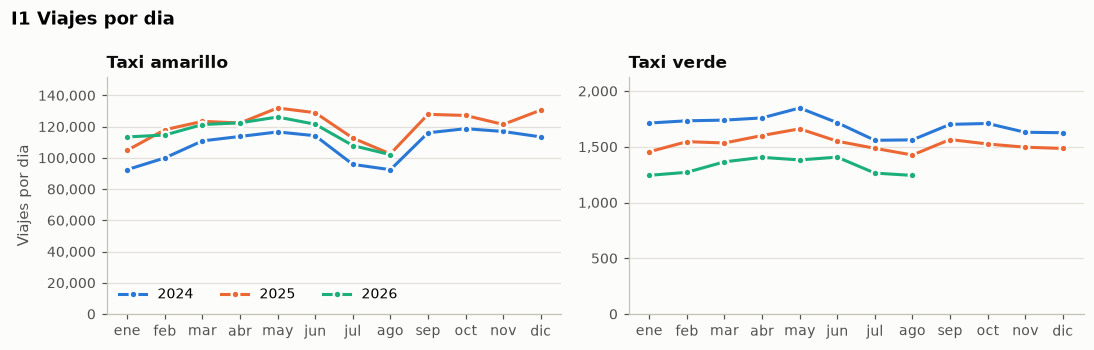

Amarillos: de 2024 a 2026, la diferencia mensual en enero–agosto va de 6.42 a 22.62 %. Valores de 2026: 102022.00–126158.00 viajes por dia. Verdes: de 2024 a 2026, la diferencia mensual en enero–agosto va de -27.38 a -18.01 %. Valores de 2026: 1243.00–1407.00 viajes por dia. Comparación descriptiva; no establece causalidad.

In [5]:
i = INDICADORES[0]
display(Markdown("**" + i["pregunta"] + "**\n\n" + i["justificacion"]))
print(evidencia["sql"][i["tabla"]])
interpretaciones[i["tabla"]] = mostrar(carpeta, i)

## I2: consulta, justificación, resultado y visualización

**Cuanto paga un pasajero en un viaje tipico?**

Describe un cobro típico con menor influencia de montos extremos que la media.

-- I2 Total cobrado en el viaje mediano, en dólares
SELECT
    periodo,
    taxi,
    round(median(total_amount), 2) AS valor
FROM viajes_validos
GROUP BY periodo, taxi
ORDER BY taxi DESC, periodo


taxi,green,yellow
periodo,,
2024-01-01,18.34,20.16
2024-02-01,18.40,20.41
2024-03-01,18.48,20.64
2024-04-01,18.85,21.00
2024-05-01,19.80,21.60
2024-06-01,19.65,21.35
2024-07-01,19.53,21.00
2024-08-01,19.85,21.00
2024-09-01,20.30,21.84


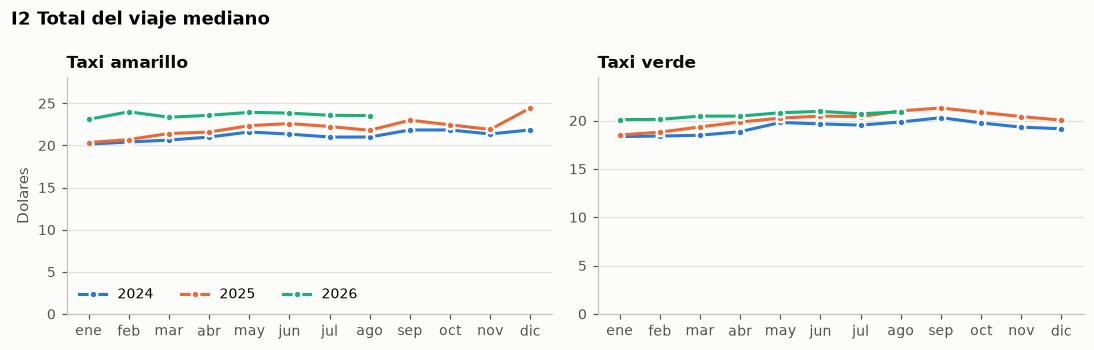

Amarillos: de 2024 a 2026, la diferencia mensual en enero–agosto va de 2.33 a 3.59 dolares. Valores de 2026: 23.10–24.00 dolares. Verdes: de 2024 a 2026, la diferencia mensual en enero–agosto va de 1.01 a 1.98 dolares. Valores de 2026: 20.10–20.95 dolares. Comparación descriptiva; no establece causalidad.

In [6]:
i = INDICADORES[1]
display(Markdown("**" + i["pregunta"] + "**\n\n" + i["justificacion"]))
print(evidencia["sql"][i["tabla"]])
interpretaciones[i["tabla"]] = mostrar(carpeta, i)

## I3: consulta, justificación, resultado y visualización

**Que parte de los viajes se pide con tarifa fija por aplicacion?**

Sigue la composición del código de pago. Los nulos se agrupan con 0 por convención, sin demostrar origen en una aplicación.

-- I3 Porcentaje de viajes Flex Fare (payment_type 0 en amarillos, nulo en verdes)
SELECT
    periodo,
    taxi,
    round(100 * avg((coalesce(payment_type, 0) = 0)::INT), 1) AS valor
FROM viajes_validos
GROUP BY periodo, taxi
ORDER BY taxi DESC, periodo


taxi,green,yellow
periodo,,
2024-01-01,6.1,4.0
2024-02-01,5.6,5.1
2024-03-01,3.8,10.6
2024-04-01,3.7,11.4
2024-05-01,3.2,10.7
2024-06-01,3.5,11.3
2024-07-01,3.2,8.9
2024-08-01,3.2,8.3
2024-09-01,3.2,12.4


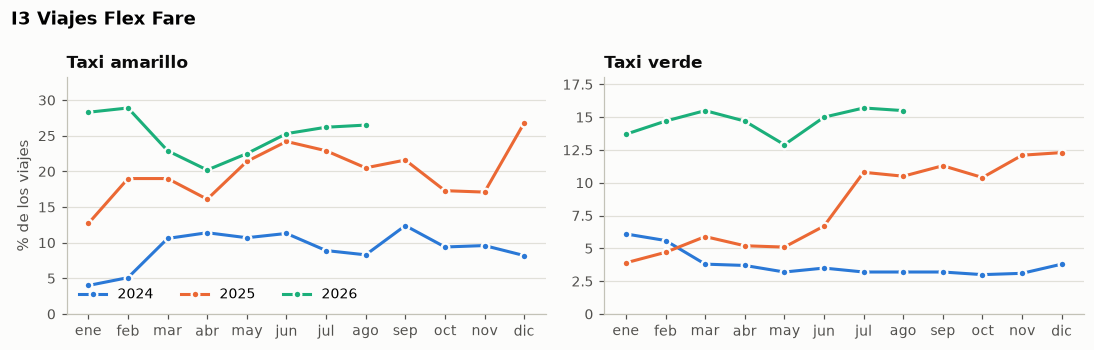

Amarillos: de 2024 a 2026, la diferencia mensual en enero–agosto va de 8.80 a 24.30 puntos porcentuales. Valores de 2026: 20.20–28.90 % de los viajes. Verdes: de 2024 a 2026, la diferencia mensual en enero–agosto va de 7.60 a 12.50 puntos porcentuales. Valores de 2026: 12.90–15.70 % de los viajes. Comparación descriptiva; no establece causalidad.

In [7]:
i = INDICADORES[2]
display(Markdown("**" + i["pregunta"] + "**\n\n" + i["justificacion"]))
print(evidencia["sql"][i["tabla"]])
interpretaciones[i["tabla"]] = mostrar(carpeta, i)

## I4: consulta, justificación, resultado y visualización

**Se sigue usando el efectivo?**

Compara un medio de pago mediante proporciones, independientemente del tamaño de cada taxi.

-- I4 Porcentaje de viajes pagados en efectivo
SELECT
    periodo,
    taxi,
    round(100 * avg((coalesce(payment_type, 0) = 2)::INT), 1) AS valor
FROM viajes_validos
GROUP BY periodo, taxi
ORDER BY taxi DESC, periodo


taxi,green,yellow
periodo,,
2024-01-01,28.6,14.7
2024-02-01,28.0,13.7
2024-03-01,29.6,13.3
2024-04-01,27.1,13.2
2024-05-01,27.2,13.3
2024-06-01,27.0,13.1
2024-07-01,27.3,14.6
2024-08-01,27.1,14.9
2024-09-01,26.0,12.1


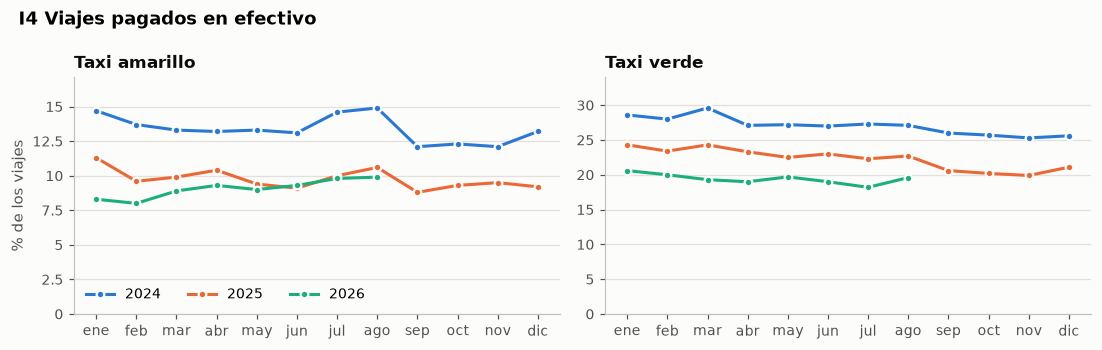

Amarillos: de 2024 a 2026, la diferencia mensual en enero–agosto va de -6.40 a -3.80 puntos porcentuales. Valores de 2026: 8.00–9.90 % de los viajes. Verdes: de 2024 a 2026, la diferencia mensual en enero–agosto va de -10.30 a -7.50 puntos porcentuales. Valores de 2026: 18.20–20.60 % de los viajes. Comparación descriptiva; no establece causalidad.

In [8]:
i = INDICADORES[3]
display(Markdown("**" + i["pregunta"] + "**\n\n" + i["justificacion"]))
print(evidencia["sql"][i["tabla"]])
interpretaciones[i["tabla"]] = mostrar(carpeta, i)

## I5: consulta, justificación, resultado y visualización

**Cuanta propina deja quien paga con tarjeta?**

Usa pagos con tarjeta y tarifa positiva; la ausencia de propina en efectivo no equivale a ausencia de propina real.

-- I5 Propina promedio como porcentaje de la tarifa en viajes pagados con tarjeta
SELECT
    periodo,
    taxi,
    round(100 * avg(tip_amount / fare_amount), 1) AS valor
FROM viajes_validos
WHERE payment_type = 1 AND fare_amount > 0
GROUP BY periodo, taxi
ORDER BY taxi DESC, periodo


taxi,green,yellow
periodo,,
2024-01-01,22.8,26.3
2024-02-01,22.5,25.4
2024-03-01,22.4,25.2
2024-04-01,22.5,25.5
2024-05-01,22.3,24.9
2024-06-01,22.1,24.7
2024-07-01,22.4,25.1
2024-08-01,22.2,24.7
2024-09-01,22.1,24.4


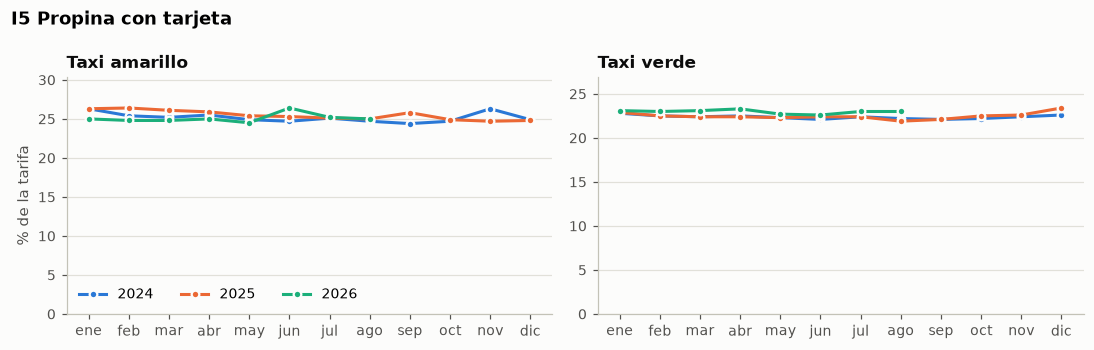

Amarillos: de 2024 a 2026, la diferencia mensual en enero–agosto va de -1.30 a 1.70 puntos porcentuales. Valores de 2026: 24.50–26.40 % de la tarifa. Verdes: de 2024 a 2026, la diferencia mensual en enero–agosto va de 0.30 a 0.80 puntos porcentuales. Valores de 2026: 22.60–23.30 % de la tarifa. Comparación descriptiva; no establece causalidad.

In [9]:
i = INDICADORES[4]
display(Markdown("**" + i["pregunta"] + "**\n\n" + i["justificacion"]))
print(evidencia["sql"][i["tabla"]])
interpretaciones[i["tabla"]] = mostrar(carpeta, i)

## I6: consulta, justificación, resultado y visualización

**A cuantos viajes alcanza el cobro por congestion?**

Mide incidencia positiva del cargo. Los nulos históricos se normalizan a cero; no permite inferir causalidad.

-- I6 Porcentaje de viajes que pagan el cargo de la zona de congestión de Manhattan (CBD)
SELECT
    periodo,
    taxi,
    round(100 * avg((cbd_congestion_fee > 0)::INT), 1) AS valor
FROM viajes_validos
GROUP BY periodo, taxi
ORDER BY taxi DESC, periodo


taxi,green,yellow
periodo,,
2024-01-01,0.0,0.0
2024-02-01,0.0,0.0
2024-03-01,0.0,0.0
2024-04-01,0.0,0.0
2024-05-01,0.0,0.0
2024-06-01,0.0,0.0
2024-07-01,0.0,0.0
2024-08-01,0.0,0.0
2024-09-01,0.0,0.0


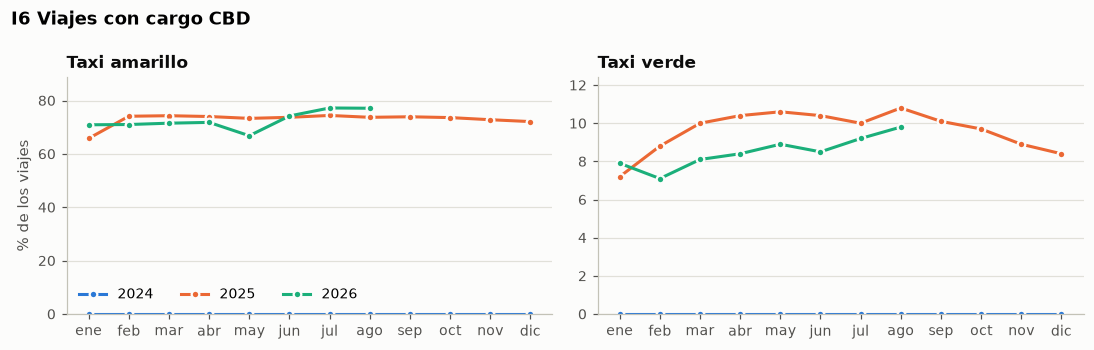

Amarillos: de 2024 a 2026, la diferencia mensual en enero–agosto va de 66.80 a 77.20 puntos porcentuales. Valores de 2026: 66.80–77.20 % de los viajes. Verdes: de 2024 a 2026, la diferencia mensual en enero–agosto va de 7.10 a 9.80 puntos porcentuales. Valores de 2026: 7.10–9.80 % de los viajes. Comparación descriptiva; no establece causalidad.

In [10]:
i = INDICADORES[5]
display(Markdown("**" + i["pregunta"] + "**\n\n" + i["justificacion"]))
print(evidencia["sql"][i["tabla"]])
interpretaciones[i["tabla"]] = mostrar(carpeta, i)

## I7: consulta, justificación, resultado y visualización

**Cambio la velocidad de los viajes dentro de Manhattan?**

Compara velocidad entre zonas de un mismo distrito y limita la influencia de valores extremos con la mediana.

-- I7 Velocidad mediana, en millas por hora, de los viajes que empiezan y terminan en Manhattan
SELECT
    v.periodo,
    v.taxi,
    round(median(v.trip_distance / (v.duracion_min / 60)), 2) AS valor
FROM viajes_validos AS v
JOIN zonas AS inicio ON v.PULocationID = inicio.zona_id
JOIN zonas AS fin ON v.DOLocationID = fin.zona_id
WHERE inicio.distrito = 'Manhattan' AND fin.distrito = 'Manhattan'
GROUP BY v.periodo, v.taxi
ORDER BY v.taxi DESC, v.periodo


taxi,green,yellow
periodo,,
2024-01-01,10.18,9.05
2024-02-01,10.20,8.89
2024-03-01,10.12,8.96
2024-04-01,10.10,8.81
2024-05-01,9.69,8.48
2024-06-01,9.99,8.75
2024-07-01,10.45,8.91
2024-08-01,10.44,8.93
2024-09-01,9.74,8.28


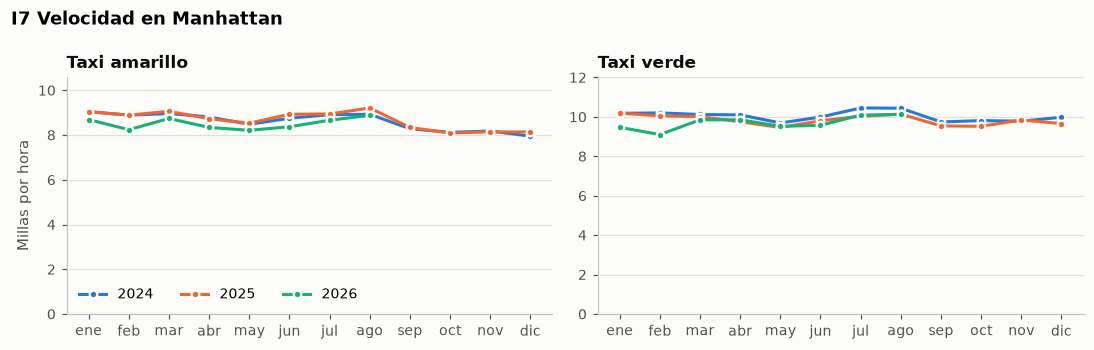

Amarillos: de 2024 a 2026, la diferencia mensual en enero–agosto va de -0.65 a -0.05 millas por hora. Valores de 2026: 8.21–8.88 millas por hora. Verdes: de 2024 a 2026, la diferencia mensual en enero–agosto va de -1.10 a -0.17 millas por hora. Valores de 2026: 9.10–10.12 millas por hora. Comparación descriptiva; no establece causalidad.

In [11]:
i = INDICADORES[6]
display(Markdown("**" + i["pregunta"] + "**\n\n" + i["justificacion"]))
print(evidencia["sql"][i["tabla"]])
interpretaciones[i["tabla"]] = mostrar(carpeta, i)

## I8: consulta, justificación, resultado y visualización

**Que peso tienen los viajes desde o hacia Newark, JFK y LaGuardia?**

Resume la participación de Newark, JFK y LaGuardia mediante sus identificadores de zona.

-- I8 Porcentaje de viajes que empiezan o terminan en Newark (1), JFK (132) o LaGuardia (138)
SELECT
    periodo,
    taxi,
    round(100 * avg((PULocationID IN (1, 132, 138) OR DOLocationID IN (1, 132, 138))::INT), 1) AS valor
FROM viajes_validos
GROUP BY periodo, taxi
ORDER BY taxi DESC, periodo


taxi,green,yellow
periodo,,
2024-01-01,3.2,9.8
2024-02-01,3.5,9.1
2024-03-01,4.0,9.5
2024-04-01,4.2,9.7
2024-05-01,4.8,10.2
2024-06-01,4.3,10.0
2024-07-01,4.3,11.3
2024-08-01,5.0,11.8
2024-09-01,4.8,10.4


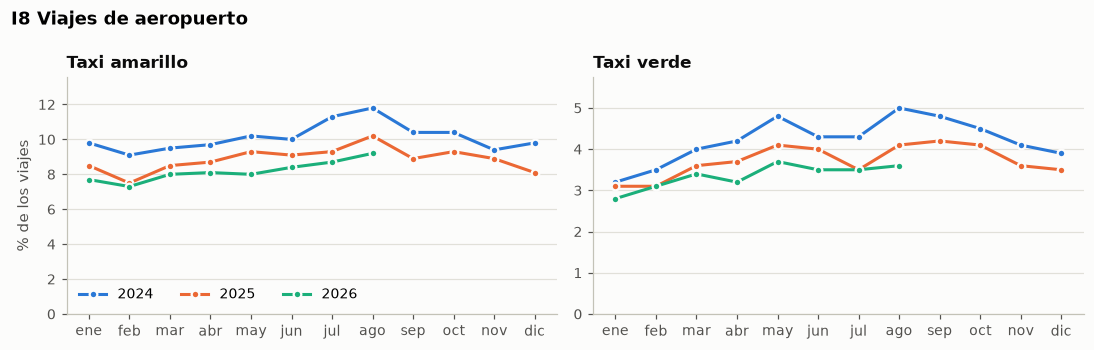

Amarillos: de 2024 a 2026, la diferencia mensual en enero–agosto va de -2.60 a -1.50 puntos porcentuales. Valores de 2026: 7.30–9.20 % de los viajes. Verdes: de 2024 a 2026, la diferencia mensual en enero–agosto va de -1.40 a -0.40 puntos porcentuales. Valores de 2026: 2.80–3.70 % de los viajes. Comparación descriptiva; no establece causalidad.

In [12]:
i = INDICADORES[7]
display(Markdown("**" + i["pregunta"] + "**\n\n" + i["justificacion"]))
print(evidencia["sql"][i["tabla"]])
interpretaciones[i["tabla"]] = mostrar(carpeta, i)

## I9: consulta, justificación, resultado y visualización

**Que parte de los registros no pasa las reglas de calidad?**

Hace explícita la selección analítica y su denominador de registros originales.

-- I9 Porcentaje de registros que no pasan las reglas de calidad de viajes_validos
WITH registros AS (
    SELECT periodo, taxi, count(*) AS total
    FROM viajes
    GROUP BY periodo, taxi
),
validos AS (
    SELECT periodo, taxi, count(*) AS validos
    FROM viajes_validos
    GROUP BY periodo, taxi
)
SELECT
    periodo,
    taxi,
    round(100 * (1 - coalesce(validos, 0) / total), 2) AS valor
FROM registros
LEFT JOIN validos USING (periodo, taxi)
ORDER BY taxi DESC, periodo


taxi,green,yellow
periodo,,
2024-01-01,6.07,3.30
2024-02-01,6.22,3.61
2024-03-01,6.16,4.06
2024-04-01,6.55,2.93
2024-05-01,6.11,2.93
2024-06-01,5.95,3.22
2024-07-01,6.81,3.44
2024-08-01,6.48,3.85
2024-09-01,6.24,4.18


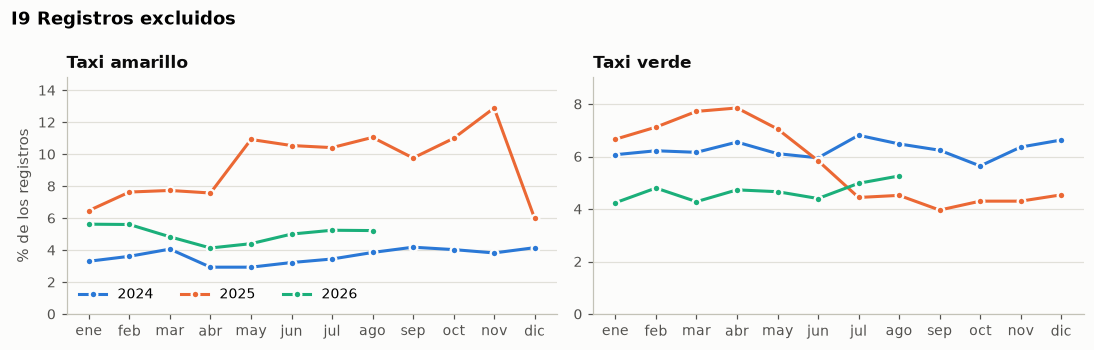

Amarillos: de 2024 a 2026, la diferencia mensual en enero–agosto va de 0.77 a 2.32 puntos porcentuales. Valores de 2026: 4.13–5.62 % de los registros. Verdes: de 2024 a 2026, la diferencia mensual en enero–agosto va de -1.88 a -1.22 puntos porcentuales. Valores de 2026: 4.24–5.26 % de los registros. Comparación descriptiva; no establece causalidad.

In [13]:
i = INDICADORES[8]
display(Markdown("**" + i["pregunta"] + "**\n\n" + i["justificacion"]))
print(evidencia["sql"][i["tabla"]])
interpretaciones[i["tabla"]] = mostrar(carpeta, i)

## Tablero y conclusiones

La publicación en Metabase requiere MB_EMAIL y MB_PASSWORD en el ambiente.
El script usa bases agregadas nuevas y conexiones de lectura, conserva IDs y
actualiza únicamente objetos marcados como propios. Ofrece filtros por taxi,
año y fechas simples. La publicación está pendiente mientras no existan
credenciales; las gráficas locales no acreditan un tablero publicado.

El aumento de proporciones de pago 0/nulo debe interpretarse con la convención
documentada. Los cambios de demanda, calidad o montos no prueban causalidad.
Las tablas completas y los hallazgos medidos quedan en el informe de la etapa.

In [14]:
documentar(config, fase)
display(pd.read_csv(carpeta / "conteos_por_anio.csv"))
print("Informe y nueve gráficas guardados. Sin repetir consultas a los viajes.")

,anio,taxi,archivos,registros_brutos,viajes_validos,exclusion_pct
0,2024,green,12,660218,618891,6.259599
1,2024,yellow,12,41169720,39673306,3.634744
2,2025,green,12,591375,557475,5.732403
3,2025,yellow,12,48722602,44148202,9.388661
4,2026,green,8,337114,321395,4.662814
5,2026,yellow,8,29703355,28223766,4.981218


Informe y nueve gráficas guardados. Sin repetir consultas a los viajes.
